# Assignment 2: Neural Network Comparison

## The Spiral Challenge

Instead of the usual "moons" dataset, I use **two interleaved spirals**. A straight line cannot separate them, so this problem needs a model that can bend its decision boundary.

### Tasks
| # | Task | Section |
|---|------|---------|
| 1 | Build a classifier on a synthetic two-class dataset | Parts 1-2 |
| 2 | Compare a linear model with a neural network using nonlinear activations | Part 3 |
| 3 | Experiment with hidden-layer size and learning rate | Part 4 |
| 4 | Record results in a comparison table | Part 4 |
| 5 | Explain which model performed best and why | Part 5 |

### Key ideas
- **Binary classification:** predict one of two classes (0 or 1).
- **Logit and sigmoid:** the model outputs a raw score, and the sigmoid turns it into a probability between 0 and 1.
- **Binary cross-entropy (BCE):** the loss for two-class problems. It punishes confident wrong answers heavily.
- **Linear vs nonlinear:** a linear model can only draw a straight boundary. A hidden layer with a nonlinear activation (ReLU, Tanh) lets the boundary curve.

In [1]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

torch.manual_seed(42)
np.random.seed(42)

print("PyTorch version:", torch.__version__)
print("Setup done")

PyTorch version: 2.14.1
Setup done


## Part 1: The Dataset

I generate two interleaved spirals with 500 points each (1000 total) and a little noise. The data is split into **train (60%)**, **validation (20%)** and **test (20%)**. Validation data is used to choose settings, and the test set is only used once at the end.

In [2]:
def make_spirals(n_per_class=500, turns=2.0, noise=0.05, seed=42):
    rng = np.random.default_rng(seed)
    r = rng.uniform(0.15, 1.0, n_per_class)        # distance from the centre
    theta = r * turns * 2 * np.pi                  # angle grows with distance -> a spiral
    arm_a = np.column_stack([r * np.cos(theta), r * np.sin(theta)])
    arm_b = -arm_a                                 # second spiral = first one rotated 180 degrees
    X = np.vstack([arm_a, arm_b]) + rng.normal(0, noise, (2 * n_per_class, 2))
    y = np.concatenate([np.zeros(n_per_class), np.ones(n_per_class)])
    return X.astype(np.float32), y.astype(np.float32)


X_np, y_np = make_spirals()
X = torch.from_numpy(X_np)
y = torch.from_numpy(y_np).unsqueeze(1)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("class counts:", int((y == 0).sum()), "and", int((y == 1).sum()))

X shape: torch.Size([1000, 2])
y shape: torch.Size([1000, 1])
class counts: 500 and 500


In [3]:
N = X.shape[0]
idx = torch.randperm(N)

n_train = int(0.6 * N)
n_val = int(0.2 * N)

train_idx = idx[:n_train]
val_idx = idx[n_train:n_train + n_val]
test_idx = idx[n_train + n_val:]

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

print("train / val / test:", len(X_train), "/", len(X_val), "/", len(X_test))
print("share of class 1 in train:", round(y_train.mean().item(), 2))

train / val / test: 600 / 200 / 200
share of class 1 in train: 0.5


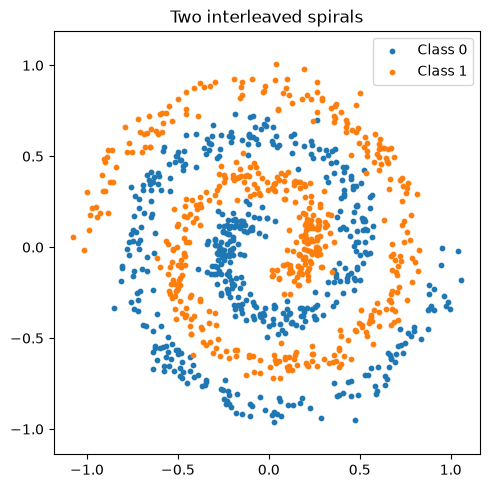

In [4]:
plt.figure(figsize=(5.5, 5.5))
for c, name, color in [(0, "Class 0", "tab:blue"), (1, "Class 1", "tab:orange")]:
    m = (y[:, 0] == c)
    plt.scatter(X[m, 0], X[m, 1], s=10, color=color, label=name)

plt.title("Two interleaved spirals")
plt.axis("equal")
plt.legend()
plt.show()

## Part 2: Baseline, a Linear Model

First a model with **no hidden layer**: `score = w1·x + w2·y + b`, followed by a sigmoid. Its decision boundary is always a **straight line**. Since the two spirals wind around each other, I expect it to perform close to guessing.

In [5]:
loss_fn = nn.BCEWithLogitsLoss()
comparison = []          # every model we train gets added to this list


def accuracy_of(model, X_, y_):
    model.eval()
    with torch.no_grad():
        pred = (torch.sigmoid(model(X_)) >= 0.5).float()
    return (pred == y_).float().mean().item()


def train_classifier(model, lr=0.05, epochs=500):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    for _ in range(epochs):
        model.train()
        opt.zero_grad()
        loss = loss_fn(model(X_train), y_train)
        loss.backward()
        opt.step()

        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(X_val), y_val).item()
        hist["train_loss"].append(loss.item())
        hist["val_loss"].append(val_loss)
        hist["train_acc"].append(accuracy_of(model, X_train, y_train))
        hist["val_acc"].append(accuracy_of(model, X_val, y_val))
    return hist


def plot_boundary(model, ax, title):
    xx, yy = np.meshgrid(np.linspace(-1.3, 1.3, 300), np.linspace(-1.3, 1.3, 300))
    grid = torch.from_numpy(np.c_[xx.ravel(), yy.ravel()].astype(np.float32))
    model.eval()
    with torch.no_grad():
        p = torch.sigmoid(model(grid)).reshape(xx.shape).numpy()
    ax.contourf(xx, yy, p, levels=20, cmap="coolwarm", alpha=0.55)
    ax.contour(xx, yy, p, levels=[0.5], colors="k", linewidths=1.5)
    ax.scatter(X[:, 0], X[:, 1], c=y[:, 0].numpy(), cmap="coolwarm", s=7, edgecolors="none")
    ax.set_title(title, fontsize=10)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])


print("Helper functions ready")

Helper functions ready


In [6]:
torch.manual_seed(0)
linear_model = nn.Linear(2, 1)
hist_linear = train_classifier(linear_model, lr=0.05, epochs=500)

tr_acc = hist_linear["train_acc"][-1]
va_acc = hist_linear["val_acc"][-1]
comparison.append({"model": "Linear (no hidden layer)", "hidden": "-", "activation": "-", "lr": 0.05,
                   "train_acc": tr_acc, "val_acc": va_acc})

print(f"Linear model | train accuracy {tr_acc:.3f} | validation accuracy {va_acc:.3f}")

Linear model | train accuracy 0.622 | validation accuracy 0.550


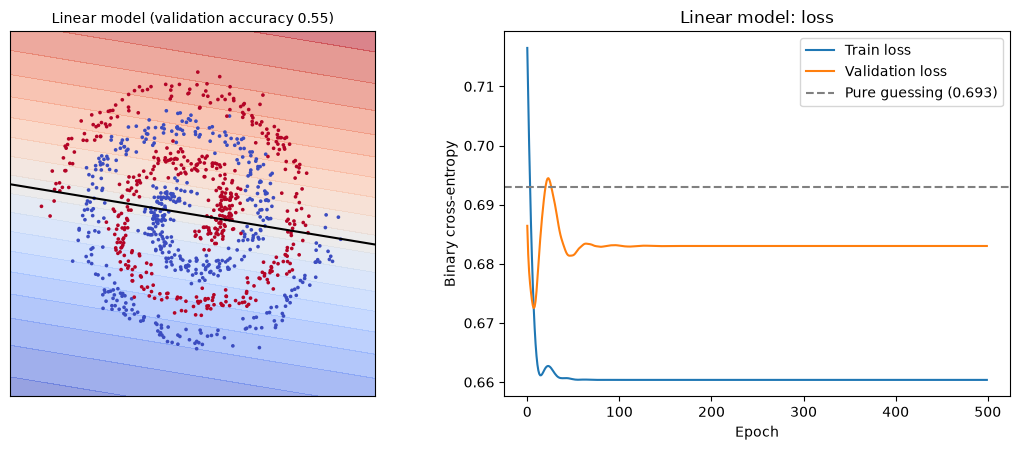

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))

plot_boundary(linear_model, ax[0], f"Linear model (validation accuracy {va_acc:.2f})")

ax[1].plot(hist_linear["train_loss"], label="Train loss")
ax[1].plot(hist_linear["val_loss"], label="Validation loss")
ax[1].axhline(0.693, color="gray", linestyle="--", label="Pure guessing (0.693)")
ax[1].set_xlabel("Epoch")
ax[1].set_ylabel("Binary cross-entropy")
ax[1].set_title("Linear model: loss")
ax[1].legend()

plt.tight_layout()
plt.savefig("linear_baseline.png", dpi=150)
plt.show()

## Part 3: Neural Networks with a Hidden Layer

I add one hidden layer of **32 neurons** and compare three versions, all trained with the same settings (learning rate 0.1, 500 epochs):

1. **Hidden layer, no activation:** still a linear model in disguise
2. **Hidden layer + ReLU**
3. **Hidden layer + Tanh**

The question: does the activation function make the difference?

In [8]:
def build_mlp(hidden=32, activation="relu"):
    acts = {"relu": nn.ReLU(), "tanh": nn.Tanh(), "none": nn.Identity()}
    return nn.Sequential(nn.Linear(2, hidden), acts[activation], nn.Linear(hidden, 1))


def record(model_name, hidden, activation, lr, hist):
    key = (model_name, hidden, activation, lr)
    comparison[:] = [r for r in comparison if (r["model"], r["hidden"], r["activation"], r["lr"]) != key]
    comparison.append({"model": model_name, "hidden": hidden, "activation": activation, "lr": lr,
                       "train_acc": hist["train_acc"][-1], "val_acc": hist["val_acc"][-1]})


nets = {}
for name, act in [("Hidden layer, no activation", "none"),
                  ("Hidden layer + ReLU", "relu"),
                  ("Hidden layer + Tanh", "tanh")]:
    torch.manual_seed(0)
    m = build_mlp(32, act)
    h = train_classifier(m, lr=0.1, epochs=500)
    nets[name] = (m, h)
    record(name, 32, act, 0.1, h)
    print(f"{name:<30} | train accuracy {h['train_acc'][-1]:.3f} | validation accuracy {h['val_acc'][-1]:.3f}")

Hidden layer, no activation    | train accuracy 0.622 | validation accuracy 0.550
Hidden layer + ReLU            | train accuracy 0.972 | validation accuracy 0.945
Hidden layer + Tanh            | train accuracy 0.997 | validation accuracy 0.910


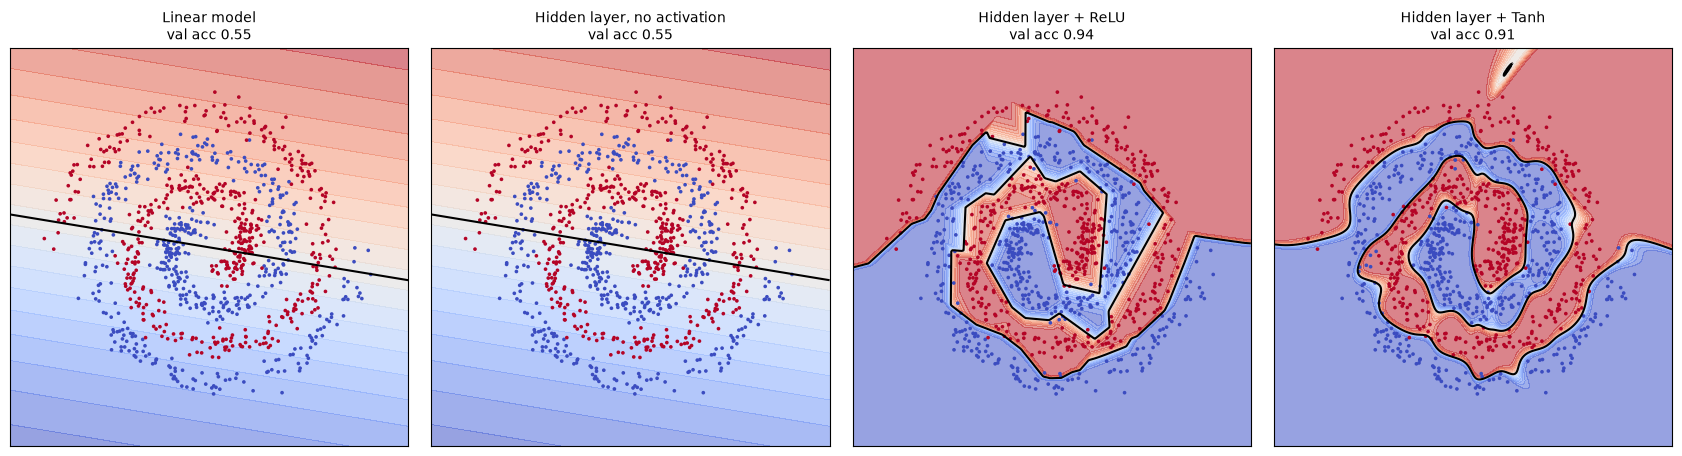

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4.4))

plot_boundary(linear_model, axes[0], f"Linear model\nval acc {hist_linear['val_acc'][-1]:.2f}")
for ax, (name, (m, h)) in zip(axes[1:], nets.items()):
    plot_boundary(m, ax, f"{name}\nval acc {h['val_acc'][-1]:.2f}")

plt.tight_layout()
plt.savefig("nonlinear_boundaries.png", dpi=150)
plt.show()

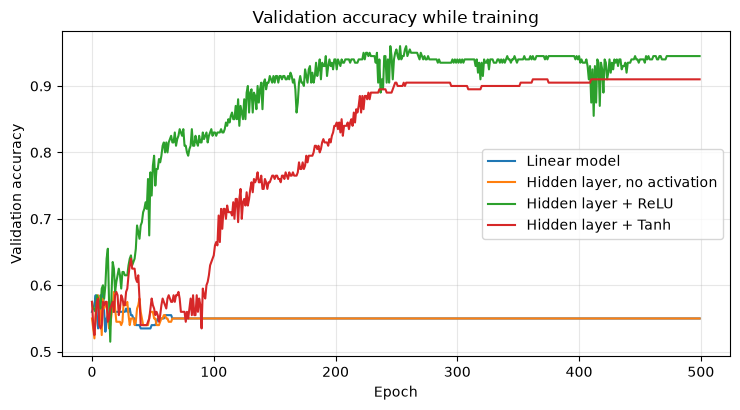

In [10]:
plt.figure(figsize=(7.5, 4.2))
plt.plot(hist_linear["val_acc"], label="Linear model")
for name, (m, h) in nets.items():
    plt.plot(h["val_acc"], label=name)
plt.xlabel("Epoch")
plt.ylabel("Validation accuracy")
plt.title("Validation accuracy while training")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("validation_accuracy_curves.png", dpi=150)
plt.show()

### What this shows

- The **linear model** and the **hidden layer without an activation** perform about the same and stay close to guessing. Stacking linear layers only gives another linear model, so the boundary is still a straight line.
- Adding a **nonlinear activation (ReLU or Tanh)** lets the boundary curve, and the accuracy jumps far above the linear models.
- The nonlinearity matters more than the extra neurons: the layer without an activation has the same number of neurons but cannot solve the problem.

## Part 4: Experiments, Hidden-Layer Size and Learning Rate

I train **24 networks** (one hidden layer) with every combination of:

- **Hidden-layer size:** 2, 8, 32, 64 neurons
- **Learning rate:** 0.001, 0.01, 0.1
- **Activation:** ReLU, Tanh

All use 500 epochs and the same starting seed. I compare them on **validation accuracy** and record every result in a table. The **gap** between train and validation accuracy shows overfitting. The test set is not used here.

In [11]:
hidden_sizes = [2, 8, 32, 64]
lrs = [0.001, 0.01, 0.1]
activations = ["relu", "tanh"]

grid_rows = []
grid_models = {}

for act in activations:
    for h in hidden_sizes:
        for lr in lrs:
            torch.manual_seed(0)
            m = build_mlp(h, act)
            hist = train_classifier(m, lr=lr, epochs=500)
            grid_models[(act, h, lr)] = m
            grid_rows.append({"model": f"MLP {act}, {h} hidden, lr {lr}", "hidden": h,
                              "activation": act, "lr": lr,
                              "train_acc": hist["train_acc"][-1], "val_acc": hist["val_acc"][-1]})
    print("finished all runs for", act)

print(len(grid_rows), "networks trained")

finished all runs for relu
finished all runs for tanh
24 networks trained


In [12]:
import csv

rows = [r for r in comparison if r["activation"] in ("-", "none")] + grid_rows
rows_sorted = sorted(rows, key=lambda r: r["val_acc"], reverse=True)

print(f"{'#':>3}  {'model':<34}{'hidden':>7}{'lr':>8}{'train':>8}{'val':>8}{'gap':>8}")
for i, r in enumerate(rows_sorted, 1):
    print(f"{i:>3}  {r['model']:<34}{str(r['hidden']):>7}{r['lr']:>8}"
          f"{r['train_acc']:>8.3f}{r['val_acc']:>8.3f}{r['train_acc'] - r['val_acc']:>8.3f}")

with open("comparison_table.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["model", "hidden", "activation", "lr", "train_acc", "val_acc"])
    for r in rows_sorted:
        w.writerow([r["model"], r["hidden"], r["activation"], r["lr"],
                    round(r["train_acc"], 4), round(r["val_acc"], 4)])

print("\nSaved comparison_table.csv")

  #  model                              hidden      lr   train     val     gap
  1  MLP relu, 64 hidden, lr 0.1            64     0.1   0.993   0.960   0.033
  2  MLP relu, 32 hidden, lr 0.1            32     0.1   0.972   0.945   0.027
  3  MLP tanh, 64 hidden, lr 0.01           64    0.01   0.963   0.935   0.028
  4  MLP tanh, 64 hidden, lr 0.1            64     0.1   0.987   0.920   0.067
  5  MLP tanh, 32 hidden, lr 0.1            32     0.1   0.997   0.910   0.087
  6  MLP relu, 64 hidden, lr 0.01           64    0.01   0.930   0.870   0.060
  7  MLP relu, 32 hidden, lr 0.01           32    0.01   0.895   0.835   0.060
  8  MLP tanh, 32 hidden, lr 0.01           32    0.01   0.873   0.825   0.048
  9  MLP tanh, 8 hidden, lr 0.1              8     0.1   0.842   0.760   0.082
 10  MLP tanh, 8 hidden, lr 0.01             8    0.01   0.642   0.640   0.002
 11  MLP relu, 2 hidden, lr 0.01             2    0.01   0.625   0.610   0.015
 12  MLP relu, 8 hidden, lr 0.1              8     0

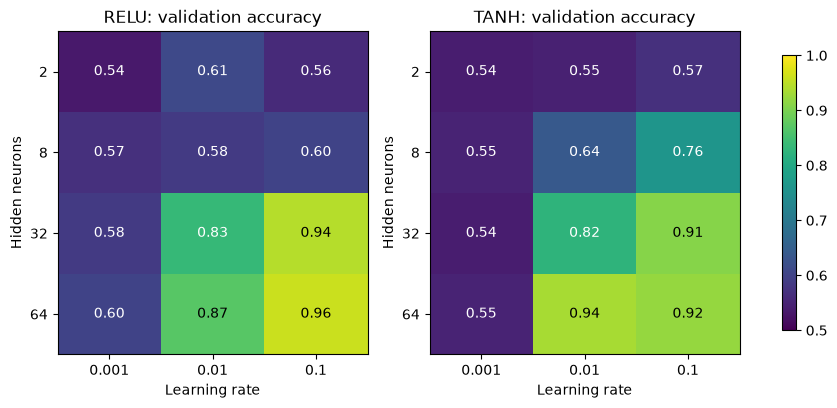

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

for ax, act in zip(axes, activations):
    grid = np.array([[next(r["val_acc"] for r in grid_rows
                           if r["activation"] == act and r["hidden"] == h and r["lr"] == lr)
                      for lr in lrs] for h in hidden_sizes])
    im = ax.imshow(grid, vmin=0.5, vmax=1.0, cmap="viridis", aspect="auto")
    ax.set_xticks(range(len(lrs)), [str(l) for l in lrs])
    ax.set_yticks(range(len(hidden_sizes)), [str(h) for h in hidden_sizes])
    ax.set_xlabel("Learning rate")
    ax.set_ylabel("Hidden neurons")
    ax.set_title(f"{act.upper()}: validation accuracy")
    for i in range(len(hidden_sizes)):
        for j in range(len(lrs)):
            ax.text(j, i, f"{grid[i, j]:.2f}", ha="center", va="center",
                    color="white" if grid[i, j] < 0.85 else "black")

fig.colorbar(im, ax=axes, shrink=0.85)
plt.savefig("grid_heatmaps.png", dpi=150, bbox_inches="tight")
plt.show()

Best by validation accuracy: MLP relu, 64 hidden, lr 0.1 | train 0.993 | val 0.960


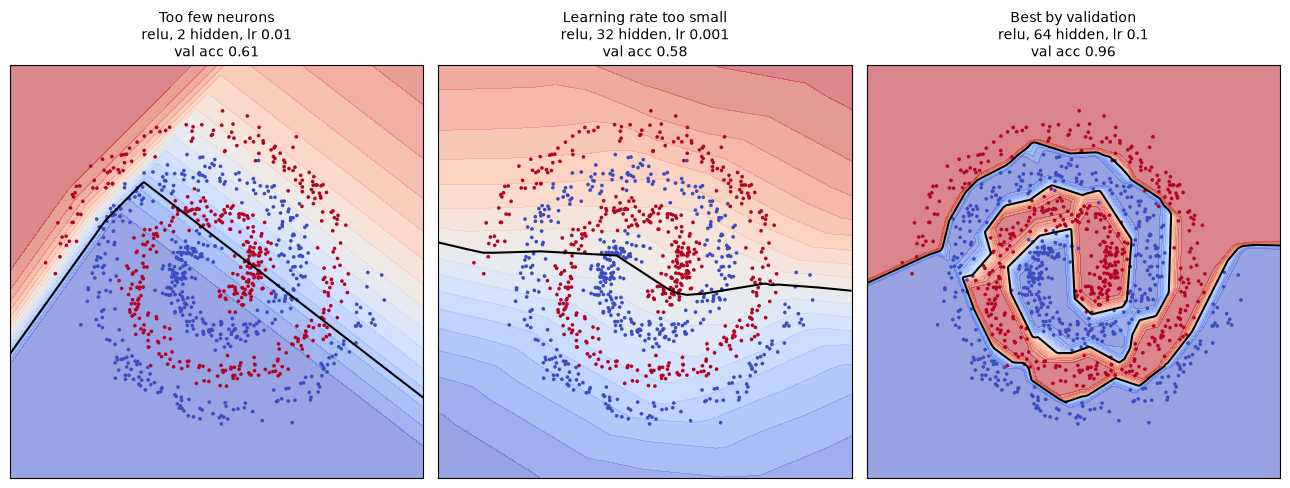

In [14]:
best_row = max(grid_rows, key=lambda r: r["val_acc"])
best_key = (best_row["activation"], best_row["hidden"], best_row["lr"])

tiny_row = max([r for r in grid_rows if r["hidden"] == 2], key=lambda r: r["val_acc"])
tiny_key = (tiny_row["activation"], 2, tiny_row["lr"])
slow_key = ("relu", 32, 0.001)

print("Best by validation accuracy:", best_row["model"],
      f"| train {best_row['train_acc']:.3f} | val {best_row['val_acc']:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(13, 4.8))
for ax, key, label in [(axes[0], tiny_key, "Too few neurons"),
                       (axes[1], slow_key, "Learning rate too small"),
                       (axes[2], best_key, "Best by validation")]:
    r = next(r for r in grid_rows if (r["activation"], r["hidden"], r["lr"]) == key)
    plot_boundary(grid_models[key], ax,
                  f"{label}\n{key[0]}, {key[1]} hidden, lr {key[2]}\nval acc {r['val_acc']:.2f}")

plt.tight_layout()
plt.savefig("boundaries_comparison.png", dpi=150)
plt.show()

In [15]:
from IPython.display import Markdown, display


def mean_val(keep):
    v = [r["val_acc"] for r in grid_rows if keep(r)]
    return sum(v) / len(v)


by_h = ", ".join(f"{h} neurons {mean_val(lambda r, h=h: r['hidden'] == h) * 100:.1f}%" for h in hidden_sizes)
by_lr = ", ".join(f"lr {lr} {mean_val(lambda r, lr=lr: r['lr'] == lr) * 100:.1f}%" for lr in lrs)
by_act = ", ".join(f"{a.upper()} {mean_val(lambda r, a=a: r['activation'] == a) * 100:.1f}%" for a in activations)
widest = max(grid_rows, key=lambda r: r["train_acc"] - r["val_acc"])

text = f"""
### What the experiments show (numbers computed from my own results)

- **Best network:** {best_row['model']} with **{best_row['val_acc'] * 100:.1f}%** validation accuracy. The linear baseline reached only **{hist_linear['val_acc'][-1] * 100:.1f}%**.
- **Average validation accuracy by hidden-layer size:** {by_h}.
- **Average validation accuracy by learning rate:** {by_lr}.
- **Average validation accuracy by activation:** {by_act}.
- **Largest train-validation gap:** {widest['model']} ({(widest['train_acc'] - widest['val_acc']) * 100:.1f} points), the clearest sign of overfitting among the 24 networks.
"""
display(Markdown(text))


### What the experiments show (numbers computed from my own results)

- **Best network:** MLP relu, 64 hidden, lr 0.1 with **96.0%** validation accuracy. The linear baseline reached only **55.0%**.
- **Average validation accuracy by hidden-layer size:** 2 neurons 56.0%, 8 neurons 61.7%, 32 neurons 77.3%, 64 neurons 80.6%.
- **Average validation accuracy by learning rate:** lr 0.001 55.9%, lr 0.01 73.1%, lr 0.1 77.8%.
- **Average validation accuracy by activation:** RELU 68.8%, TANH 69.0%.
- **Largest train-validation gap:** MLP tanh, 32 hidden, lr 0.1 (8.7 points), the clearest sign of overfitting among the 24 networks.


## Part 5: Final Test Results

The test set (200 points) was not used for training or for choosing settings. I evaluate **three models** on it: the **linear model**, the **hidden layer without activation**, and the **best network** chosen by validation accuracy. For each I report **accuracy, precision, recall, F1** and the **confusion matrix**."

In [16]:
from sklearn.metrics import ConfusionMatrixDisplay


def predict_labels(model, X_):
    model.eval()
    with torch.no_grad():
        return (torch.sigmoid(model(X_)) >= 0.5).int().flatten().numpy()


y_true = y_test.int().flatten().numpy()
best_model = grid_models[best_key]

final_models = [
    ("Linear model", linear_model),
    ("Hidden layer, no activation", nets["Hidden layer, no activation"][0]),
    (f"Best network ({best_row['activation']}, {best_row['hidden']} hidden, lr {best_row['lr']})", best_model),
]

final_rows = []
print(f"{'model':<46}{'accuracy':>9}{'precision':>10}{'recall':>8}{'F1':>8}")
for name, m in final_models:
    p = predict_labels(m, X_test)
    row = {"model": name,
           "accuracy": accuracy_score(y_true, p),
           "precision": precision_score(y_true, p, zero_division=0),
           "recall": recall_score(y_true, p, zero_division=0),
           "f1": f1_score(y_true, p, zero_division=0),
           "pred": p}
    final_rows.append(row)
    print(f"{name:<46}{row['accuracy']:>9.3f}{row['precision']:>10.3f}{row['recall']:>8.3f}{row['f1']:>8.3f}")

model                                          accuracy precision  recall      F1
Linear model                                      0.575     0.632   0.593   0.612
Hidden layer, no activation                       0.575     0.632   0.593   0.612
Best network (relu, 64 hidden, lr 0.1)            0.955     0.956   0.965   0.960


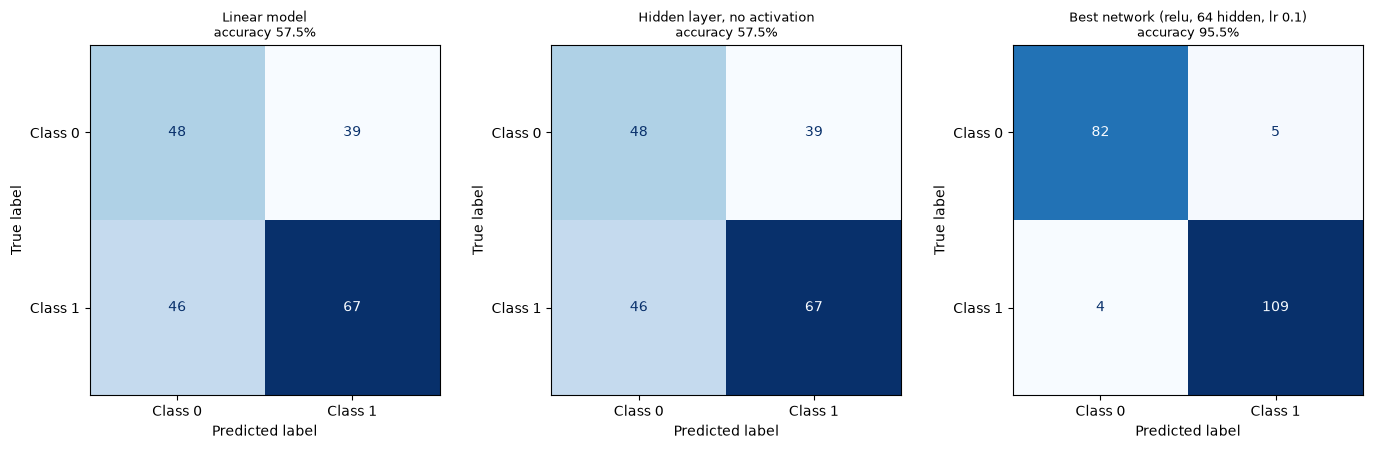

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
for ax, r in zip(axes, final_rows):
    cm = confusion_matrix(y_true, r["pred"])
    ConfusionMatrixDisplay(cm, display_labels=["Class 0", "Class 1"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{r['model']}\naccuracy {r['accuracy'] * 100:.1f}%", fontsize=9)

plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=150)
plt.show()

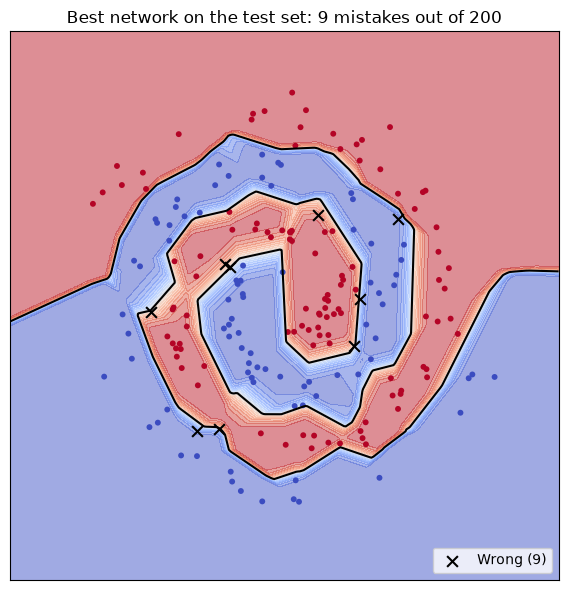

In [18]:
best_pred = final_rows[2]["pred"]
wrong = best_pred != y_true

xx, yy = np.meshgrid(np.linspace(-1.3, 1.3, 300), np.linspace(-1.3, 1.3, 300))
grid = torch.from_numpy(np.c_[xx.ravel(), yy.ravel()].astype(np.float32))
best_model.eval()
with torch.no_grad():
    prob_map = torch.sigmoid(best_model(grid)).reshape(xx.shape).numpy()

fig, ax = plt.subplots(figsize=(6, 6))
ax.contourf(xx, yy, prob_map, levels=20, cmap="coolwarm", alpha=0.5)
ax.contour(xx, yy, prob_map, levels=[0.5], colors="k", linewidths=1.5)
ax.scatter(X_test[~wrong, 0], X_test[~wrong, 1], c=y_true[~wrong], cmap="coolwarm", s=18, edgecolors="none")
ax.scatter(X_test[wrong, 0], X_test[wrong, 1], c="black", marker="x", s=60, label=f"Wrong ({int(wrong.sum())})")
ax.set_title(f"Best network on the test set: {int(wrong.sum())} mistakes out of {len(y_true)}")
ax.set_aspect("equal")
ax.set_xticks([])
ax.set_yticks([])
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("test_mistakes.png", dpi=150)
plt.show()

In [19]:
from IPython.display import Markdown, display


def avg_by(field, values):
    return {v: float(np.mean([r["val_acc"] for r in grid_rows if r[field] == v])) for v in values}


h_avg = avg_by("hidden", hidden_sizes)
lr_avg = avg_by("lr", lrs)
a_avg = avg_by("activation", activations)
best_h = max(h_avg, key=h_avg.get)
best_lr = max(lr_avg, key=lr_avg.get)
best_act = max(a_avg, key=a_avg.get)

lin_r, noact_r, best_r = final_rows
table_rows = "\n".join(
    f"| {r['model']} | {r['accuracy'] * 100:.1f}% | {r['precision']:.3f} | {r['recall']:.3f} | {r['f1']:.3f} |"
    for r in final_rows
)
val_vs_test = best_row["val_acc"] * 100 - best_r["accuracy"] * 100

text = f"""
## Part 6: Which Model Performed Best, and Why?

### Final comparison on the test set (200 points)

| Model | Accuracy | Precision | Recall | F1 |
|-------|----------|-----------|--------|----|
{table_rows}

### Verdict

- **Best model:** {best_r['model']}, with **{best_r['accuracy'] * 100:.1f}%** test accuracy. The linear model reached **{lin_r['accuracy'] * 100:.1f}%** and the hidden layer without an activation **{noact_r['accuracy'] * 100:.1f}%**.
- **It generalizes:** validation accuracy was {best_row['val_acc'] * 100:.1f}% and test accuracy {best_r['accuracy'] * 100:.1f}% (a difference of {abs(val_vs_test):.1f} points), so the choice made on validation data held up on unseen data.
- **Across all 24 networks, on average:** the best hidden-layer size was **{best_h} neurons**, the best learning rate **{best_lr}**, and the best activation **{best_act.upper()}**.
"""
display(Markdown(text))


## Part 6: Which Model Performed Best, and Why?

### Final comparison on the test set (200 points)

| Model | Accuracy | Precision | Recall | F1 |
|-------|----------|-----------|--------|----|
| Linear model | 57.5% | 0.632 | 0.593 | 0.612 |
| Hidden layer, no activation | 57.5% | 0.632 | 0.593 | 0.612 |
| Best network (relu, 64 hidden, lr 0.1) | 95.5% | 0.956 | 0.965 | 0.960 |

### Verdict

- **Best model:** Best network (relu, 64 hidden, lr 0.1), with **95.5%** test accuracy. The linear model reached **57.5%** and the hidden layer without an activation **57.5%**.
- **It generalizes:** validation accuracy was 96.0% and test accuracy 95.5% (a difference of 0.5 points), so the choice made on validation data held up on unseen data.
- **Across all 24 networks, on average:** the best hidden-layer size was **64 neurons**, the best learning rate **0.1**, and the best activation **TANH**.


### Why did the best network win?

1. **The data is not linearly separable.** The two spirals wind around each other, so no straight line can put one spiral on each side. Every linear model is limited to about the accuracy of guessing, whatever its settings.
2. **A hidden layer needs an activation.** Without one, two linear layers collapse into a single linear function. That is why the layer without an activation behaves like the linear baseline even with 32 neurons.
3. **Nonlinear activations let the boundary bend.** With ReLU or Tanh, each hidden neuron adds a bend to the boundary, and a bigger hidden layer can combine more bends to follow the spiral arms. Too few neurons (for example 2) cannot draw a shape that complex, which is **underfitting**.
4. **Learning rate decides whether training finishes.** A very small rate is stable but too slow to converge within 500 epochs, so those networks stay weak. A larger rate learned much faster in these experiments, as the heatmaps show.
5. **Validation data chose the model, test data judged it.** Picking the best settings on validation data and reporting a separate test score avoids fooling ourselves with a result tuned on the same data.

### Limitations
- The test set has only 200 points, so one mistake changes accuracy by 0.5 points, and the exact ranking of close models could change with another random split.
- Every network was trained once with one random seed.
- The data is synthetic. Real data has more noise and less structure.

### Task checklist
| Task | Where |
|------|-------|
| 1. Classifier on a synthetic two-class dataset | Parts 1-3 |
| 2. Linear model vs neural network with nonlinear activations | Parts 2-3 |
| 3. Hidden-layer size and learning rate experiments | Part 4 |
| 4. Results in a comparison table | Part 4 (and `comparison_table.csv`) |
| 5. Which model is best and why | Part 6 |